# Hotel Booking Demand Analysis

**Author:** Mark Ayman  
**Objective:** Analyze the Hotel Booking dataset, clean the data, and extract meaningful insights that could help improve business decisions.

## Introduction

This notebook performs a full data analysis workflow on the Hotel Booking dataset.

The goal of this analysis is to:
- Understand the dataset structure
- Clean and preprocess the data
- Perform exploratory data analysis (EDA)
- Identify patterns and trends
- Generate business insights

## import libraries

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## load dataset

In [ ]:
data = pd.read_csv( kagglehub.dataset_download("jessemostipak/hotel-booking-demand") +"/hotel_bookings.csv")
df = data
df

Using Colab cache for faster access to the 'hotel-booking-demand' dataset.


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


## Data Overview

In [ ]:
df.shape

(119390, 32)

In [ ]:
col = df.columns
col

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.nunique()

,0
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


In [ ]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df.describe(include = 'O')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [ ]:
df.duplicated().sum()

np.int64(31994)

In [ ]:
df.isnull().sum()

,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


## Data Cleaning

In [ ]:
df['country'] = df['country'].fillna('Unknown')

In [ ]:
df = df.fillna(0)

In [ ]:
# df = df.drop_duplicates()

In [ ]:
df['is_canceled'] = df['is_canceled'].astype('bool')
df['is_repeated_guest'] = df['is_repeated_guest'].astype('bool')
df['children'] = df['children'].astype('int')
df['agent'] = df['agent'].astype('int')
df['company'] = df['company'].astype('int')

In [ ]:
df['month_number'] = pd.to_datetime(df['arrival_date_month'], format='%B').dt.month
df['arrival_date'] = pd.to_datetime(dict(
    year = df['arrival_date_year'],
    month = df['month_number'],
    day = df['arrival_date_day_of_month']
))

## EDA

In [ ]:
print(f'Number of reservations: {df["hotel"].count()}')

Number of reservations: 119390


In [ ]:
df.groupby('hotel').size()

,0
hotel,
City Hotel,79330
Resort Hotel,40060


In [ ]:
sun = df.groupby('hotel')['is_canceled'].value_counts()
sun

hotel         is_canceled
City Hotel    False          46228
              True           33102
Resort Hotel  False          28938
              True           11122
Name: count, dtype: int64

In [ ]:
df.groupby('country').size()

,0
country,
ABW,2
AGO,362
AIA,1
ALB,12
AND,7
...,...
VGB,1
VNM,8
ZAF,80


In [ ]:
top_10_countries = df.groupby('country').size().sort_values(ascending = False).head(10)
top_10_countries

,0
country,
PRT,48590
GBR,12129
FRA,10415
ESP,8568
DEU,7287
ITA,3766
IRL,3375
BEL,2342
BRA,2224


In [ ]:
df.groupby('hotel')['adr'].mean()

,adr
hotel,
City Hotel,105.304465
Resort Hotel,94.952930


In [ ]:
month_order = df.groupby(['month_number','arrival_date_month']).size()
month_order

,,0
month_number,arrival_date_month,
1,January,5929
2,February,8068
3,March,9794
4,April,11089
5,May,11791
6,June,10939
7,July,12661
8,August,13877
9,September,10508


In [ ]:
df.groupby('market_segment').size()

,0
market_segment,
Aviation,237
Complementary,743
Corporate,5295
Direct,12606
Groups,19811
Offline TA/TO,24219
Online TA,56477
Undefined,2


## Data Visualization

In [ ]:
fig = px.sunburst(
    sun.reset_index(),
    path=['hotel', 'is_canceled'],
    values='count'
)
fig.show()

<Axes: xlabel='country'>

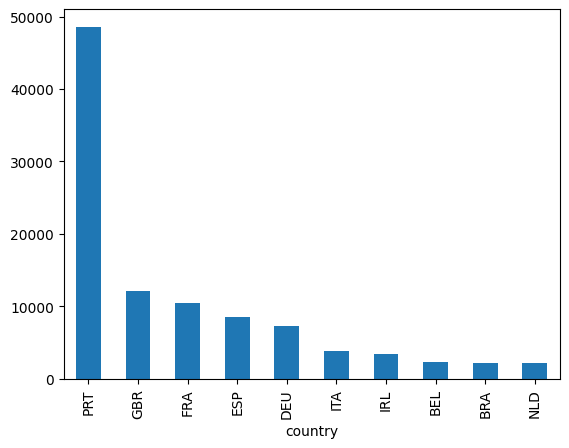

In [ ]:
top_10_countries.plot(kind = 'bar')

<Axes: xlabel='month_number,arrival_date_month'>

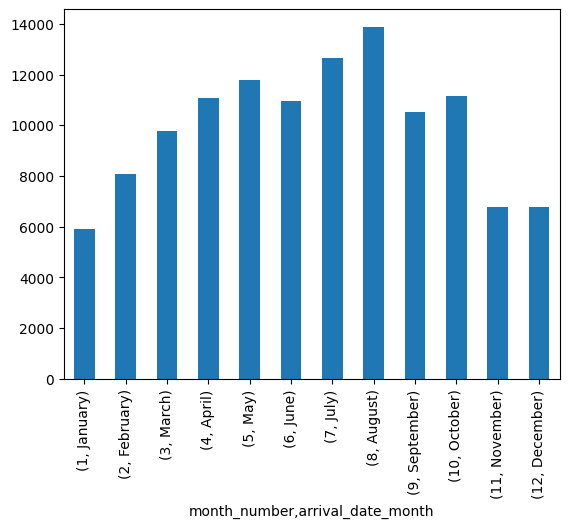

In [ ]:
month_order.plot(kind = 'bar')

## Key Insights

1. High Cancellation Rate

- Around ~30–35% of bookings are canceled.

- Cancellations are a major business challenge because they affect occupancy and revenue planning.

2. Popular Hotel Types

- City Hotel bookings make up a larger share than Resort Hotel bookings (often >60%).

- Resort Hotels show more seasonal trends – busier in summer months, while City Hotels are more consistent year‑round.

3. Seasonality and Booking Timing

- Peak booking months: July and August have the most reservations.

- Lower demand at the beginning and end of the year.

4. Guest Origins

- Most guests come from a handful of countries — notably Portugal, the UK, France, Spain, and Germany.

5. Guest Stay Patterns

- Most guests stay for 1–3 nights.

- Resort hotel guests tend to stay slightly longer than city hotel guests.

6. Guest Type & Booking Characteristics

- Couples or two adults are the most common booking type.

- Lead time (how far in advance the booking was made) influences cancellations — longer lead times often show higher cancellation rates.

7. Pricing and Revenue Patterns

- Average daily rates vary by season and date; typically higher during high‑demand months and weekends.

- Some analyses show ADR increases around the start and end of months.

## Conclusions

### Cancellation Prediction

Machine learning models can predict cancellations with decent accuracy using features like lead time, booking channel, guest type, etc.

### Operational Decisions

Hotels can adjust pricing strategies, overbooking policies, and marketing campaigns based on seasonal and booking channel patterns.

### Revenue Management

Understanding peak months and guest profiles helps optimize rates and allocate resources more effectively.